# DS201 - Lab 03: Mạng neural hồi quy (LSTM, GRU, BiLSTM)

**Họ tên:** Nguyễn Việt Tiến
**MSSV:** 24521777

Nội dung bài làm:
- Bài 1: LSTM 5 lớp phân loại cảm xúc trên UIT-VSFC
- Bài 2: GRU 5 lớp trên cùng bài toán, so sánh với LSTM và baseline TF-IDF
- Bài 3: Encoder 5 lớp BiLSTM cho bài toán NER trên PhoNER_COVID19
- Bài 4 (tùy chọn): ảnh hưởng của số lớp (1, 2, 5 lớp GRU)

Cấu hình chung theo đề: 5 lớp, hidden 256, embedding 300 (học từ đầu), dropout 0.3, Adam lr 1e-3, batch 32, clip gradient 1.0, tối đa 10 epoch, seed 42. Chọn checkpoint theo F1 trên dev, test chỉ chấm 1 lần với checkpoint đã chọn.

## 0. Chuẩn bị

In [1]:
%pip install -q seqeval

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, json, time, copy, random, hashlib, urllib.request
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)
from seqeval.metrics import classification_report as seq_report
from seqeval.metrics import f1_score as seq_f1, precision_score as seq_precision, recall_score as seq_recall
from seqeval.scheme import IOB2

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# cấu hình chung cho Bài 1, 2, 3 (theo đề)
CFG = dict(emb_dim=300, hidden=256, layers=5, dropout=0.3,
           lr=1e-3, batch_size=32, max_epochs=10, clip=1.0, seed=42)

DATA_DIR = Path("data")
CKPT_DIR = Path("checkpoints")
CKPT_DIR.mkdir(exist_ok=True)

set_seed(CFG["seed"])
print("torch :", torch.__version__)
print("device:", DEVICE, "-", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")
print("CFG   :", CFG)

torch : 2.14.1+cu130
device: cuda - Tesla T4
CFG   : {'emb_dim': 300, 'hidden': 256, 'layers': 5, 'dropout': 0.3, 'lr': 0.001, 'batch_size': 32, 'max_epochs': 10, 'clip': 1.0, 'seed': 42}


### 0.1. Tải dữ liệu

UIT-VSFC lấy từ Google Drive, PhoNER_COVID19 (bản syllable) lấy từ GitHub của VinAI. Mỗi file được kiểm tra SHA-256 để chắc là đúng phiên bản dữ liệu của đề. Dữ liệu chỉ để trên máy, không đưa lên GitHub (PhoNER không cho phân phối lại).

In [3]:
GDRIVE = "https://drive.google.com/uc?export=download&id="
PHONER = "https://raw.githubusercontent.com/VinAIResearch/PhoNER_COVID19/main/data/syllable/"
FILES = {
    "uit-vsfc/train.json": (GDRIVE + "1eJdEStCQBf3GtbOIQfIR2iS-Wb3nlfJX",
                            "e41e65672f2ade65ee8d2d394659a2bfeabbce987f0d2ad9e19998068a78fc1e"),
    "uit-vsfc/dev.json":   (GDRIVE + "1UWbzHFeUPu4AuofOEy0Fo0SFotVZHzUe",
                            "ab781a38209c17e640e077f83d82ecb9ea4f3469e63fc6ec2a232b0da6fbe823"),
    "uit-vsfc/test.json":  (GDRIVE + "1g4imdabNbswIu91K6zKFGalkjDBBqaQq",
                            "14a6c5697907084086551a17c76e908dad88f2dc3b8be720c9880c8fc1212aa6"),
    "phoner/train.json":   (PHONER + "train_syllable.json",
                            "fb4097f6ac956a03e484319898db0dafc7283c135cd7888f803ad26a5a253419"),
    "phoner/dev.json":     (PHONER + "dev_syllable.json",
                            "c74393fb5d1547d51ddda175830892ca62a7efa2d93291b21a35cb21bfee612e"),
    "phoner/test.json":    (PHONER + "test_syllable.json",
                            "4b677028d6db5e1dab74d727d88b719454da60cfeaba681d9ee401fc83b04c77"),
}

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

for name, (url, expected) in FILES.items():
    path = DATA_DIR / name
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        with urllib.request.urlopen(url, timeout=90) as res:
            path.write_bytes(res.read())
    status = "ok" if sha256(path) == expected else "SAI CHECKSUM"
    print(f"{name:22s} {path.stat().st_size / 1024:8.0f} KB  {status}")
    assert status == "ok", f"File {name} không đúng phiên bản, xóa đi rồi tải lại"

uit-vsfc/train.json        1975 KB  ok
uit-vsfc/dev.json           268 KB  ok
uit-vsfc/test.json          546 KB  ok
phoner/train.json          2647 KB  ok
phoner/dev.json            1160 KB  ok
phoner/test.json           1764 KB  ok


In [4]:
SPLITS = ["train", "dev", "test"]

def read_vsfc(split):
    # mỗi file UIT-VSFC là 1 mảng JSON
    return json.loads((DATA_DIR / "uit-vsfc" / f"{split}.json").read_text(encoding="utf-8-sig"))

def read_phoner(split):
    # PhoNER là JSON Lines: mỗi dòng 1 câu
    lines = (DATA_DIR / "phoner" / f"{split}.json").read_text(encoding="utf-8-sig").splitlines()
    return [json.loads(line) for line in lines if line.strip()]

vsfc = {s: read_vsfc(s) for s in SPLITS}
phoner = {s: read_phoner(s) for s in SPLITS}

LABELS = ["negative", "neutral", "positive"]
stats = []
for s in SPLITS:
    cnt = Counter(r["sentiment"] for r in vsfc[s])
    lens = [len(r["sentence"].split()) for r in vsfc[s]]
    stats.append({"split": s, "VSFC (câu)": len(vsfc[s]), **{k: cnt[k] for k in LABELS},
                  "số từ TB": round(np.mean(lens), 1), "PhoNER (câu)": len(phoner[s]),
                  "PhoNER số token TB": round(np.mean([len(r["words"]) for r in phoner[s]]), 1)})
display(pd.DataFrame(stats))

assert all(len(r["words"]) == len(r["tags"]) for s in SPLITS for r in phoner[s])
print("Tỉ lệ neutral trên train:", round(stats[0]["neutral"] / stats[0]["VSFC (câu)"] * 100, 1), "%")

,split,VSFC (câu),negative,neutral,positive,số từ TB,PhoNER (câu),PhoNER số token TB
0,train,11426,5325,458,5643,14.3,5027,33.3
1,dev,1583,705,73,805,13.7,2000,35.7
2,test,3166,1409,167,1590,14.2,3000,36.1


Tỉ lệ neutral trên train: 4.0 %


## 1. Phần dùng chung: từ điển, Dataset, mô hình, vòng lặp train

Phần này em viết 1 lần rồi dùng lại cho cả 3 bài:
- `Vocab`: từ điển xây từ tập train (từ xuất hiện từ 2 lần trở lên), id 0 là PAD, id 1 là UNK.
- `SentimentData`, `NerData`: Dataset cho 2 bài toán, `pad_collate` dùng chung để ghép batch.
- `RNNEncoder`: embedding + LSTM/GRU nhiều lớp, có packing để RNN không chạy qua các ô đệm.
- `Trainer`: vòng lặp train, ghi lại loss và F1 dev mỗi epoch, giữ checkpoint có F1 dev cao nhất.

In [5]:
PAD_ID, UNK_ID = 0, 1
IGNORE = -100          # nhãn đệm cho NER, loss sẽ bỏ qua

class Vocab:
    def __init__(self, tokens):
        self.itos = ["<pad>", "<unk>"] + list(tokens)
        self.stoi = {t: i for i, t in enumerate(self.itos)}

    @classmethod
    def from_corpus(cls, sentences, min_freq=2):
        freq = Counter(tok for sent in sentences for tok in sent)
        return cls(sorted(t for t, c in freq.items() if c >= min_freq))

    def __len__(self):
        return len(self.itos)

    def lookup(self, tokens):
        ids = [self.stoi.get(t, UNK_ID) for t in tokens]
        return ids or [UNK_ID]     # câu rỗng vẫn cần 1 token để packing không lỗi

def split_words(text):
    return text.lower().split()

class SentimentData(Dataset):
    def __init__(self, rows, vocab):
        self.texts = [r["sentence"] for r in rows]
        self.ids = [torch.tensor(vocab.lookup(split_words(t))) for t in self.texts]
        self.labels = [LABELS.index(r["sentiment"]) for r in rows]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.ids[i], torch.tensor(self.labels[i])

class NerData(Dataset):
    def __init__(self, rows, vocab, tag2id):
        # PhoNER đã tách sẵn token, giữ nguyên chữ hoa và dấu câu
        self.ids = [torch.tensor(vocab.lookup(r["words"])) for r in rows]
        self.tags = [torch.tensor([tag2id[t] for t in r["tags"]]) for r in rows]

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        return self.ids[i], self.tags[i]

def pad_collate(batch):
    xs, ys = zip(*batch)
    lengths = torch.tensor([len(x) for x in xs])        # độ dài thật, lấy trước khi đệm
    x = pad_sequence(xs, batch_first=True, padding_value=PAD_ID)
    if ys[0].dim() == 0:                                # phân loại câu: 1 nhãn / câu
        y = torch.stack(ys)
    else:                                               # NER: 1 nhãn / token
        y = pad_sequence(ys, batch_first=True, padding_value=IGNORE)
    return x, lengths, y

def make_loader(ds, shuffle=False):
    return DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle, collate_fn=pad_collate,
                      generator=torch.Generator().manual_seed(CFG["seed"]))

In [6]:
sent_vocab = Vocab.from_corpus(split_words(r["sentence"]) for r in vsfc["train"])
cls_data = {s: SentimentData(vsfc[s], sent_vocab) for s in SPLITS}
cls_loader = {s: make_loader(cls_data[s], shuffle=(s == "train")) for s in SPLITS}

print("Kích thước từ điển UIT-VSFC:", len(sent_vocab))
oov = np.mean([i == UNK_ID for x in cls_data["dev"].ids for i in x.tolist()])
print(f"Tỉ lệ từ lạ (UNK) trên dev: {oov * 100:.2f} %")
x, lengths, y = next(iter(cls_loader["train"]))
print("1 batch:", tuple(x.shape), "| lengths 5 câu đầu:", lengths[:5].tolist(), "| nhãn:", y[:5].tolist())

Kích thước từ điển UIT-VSFC: 1535
Tỉ lệ từ lạ (UNK) trên dev: 0.78 %
1 batch: (32, 45) | lengths 5 câu đầu: [12, 6, 9, 10, 4] | nhãn: [0, 0, 2, 0, 1]


In [7]:
class RNNEncoder(nn.Module):
    # embedding + RNN nhiều lớp, có packing
    def __init__(self, vocab_size, rnn_type, emb_dim, hidden, layers, dropout, bidirectional=False):
        super().__init__()
        self.rnn_type = rnn_type
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        rnn_cls = nn.LSTM if rnn_type == "lstm" else nn.GRU
        self.rnn = rnn_cls(emb_dim, hidden, num_layers=layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0,
                           bidirectional=bidirectional)
        self.out_dim = hidden * (2 if bidirectional else 1)

    def forward(self, ids, lengths):
        emb = self.embedding(ids)
        # lengths phải ở CPU; enforce_sorted=False để không cần sắp batch theo độ dài
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, state = self.rnn(packed)
        h_n = state[0] if self.rnn_type == "lstm" else state    # LSTM trả về (h_n, c_n)
        return out, h_n

class SentimentRNN(nn.Module):
    def __init__(self, vocab_size, rnn_type, n_classes=3, **kw):
        super().__init__()
        self.encoder = RNNEncoder(vocab_size, rnn_type, **kw)
        self.dropout = nn.Dropout(kw["dropout"])
        self.head = nn.Linear(self.encoder.out_dim, n_classes)

    def forward(self, ids, lengths):
        _, h_n = self.encoder(ids, lengths)
        sent_vec = h_n[-1]            # trạng thái cuối của lớp trên cùng = vector đại diện câu
        return self.head(self.dropout(sent_vec))     # trả logits, không softmax

class LSTMSentiment(SentimentRNN):
    def __init__(self, vocab_size, **kw):
        super().__init__(vocab_size, "lstm", **kw)

class GRUSentiment(SentimentRNN):
    def __init__(self, vocab_size, **kw):
        super().__init__(vocab_size, "gru", **kw)

class BiLSTMTagger(nn.Module):
    def __init__(self, vocab_size, n_tags, **kw):
        super().__init__()
        self.encoder = RNNEncoder(vocab_size, "lstm", bidirectional=True, **kw)
        self.dropout = nn.Dropout(kw["dropout"])
        self.head = nn.Linear(self.encoder.out_dim, n_tags)     # 2 x 256 = 512 -> 21 nhãn

    def forward(self, ids, lengths):
        out, _ = self.encoder(ids, lengths)
        # mở gói lại, giữ đúng chiều dài để logits cùng shape với tensor nhãn
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=ids.size(1))
        return self.head(self.dropout(out))

MODEL_KW = dict(emb_dim=CFG["emb_dim"], hidden=CFG["hidden"], layers=CFG["layers"], dropout=CFG["dropout"])

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def rnn_params_by_hand(gates, inp, hidden, layers, bidirectional=False):
    # mỗi lớp, mỗi chiều: gates x (H x (I + H) + 2H), PyTorch có 2 vector bias
    d = 2 if bidirectional else 1
    total = 0
    for layer in range(layers):
        i = inp if layer == 0 else hidden * d
        total += d * gates * (hidden * (i + hidden) + 2 * hidden)
    return total

In [8]:
# kiểm tra packing: cùng 1 câu, đệm tới 8 ô và 64 ô phải cho cùng logits
set_seed(CFG["seed"])
check_model = LSTMSentiment(len(sent_vocab), **MODEL_KW).to(DEVICE).eval()
sent = torch.tensor(sent_vocab.lookup(split_words("giảng viên dạy rất nhiệt tình")))
n = len(sent)
with torch.no_grad():
    outs = []
    for total in (8, 64):
        ids = torch.cat([sent, torch.zeros(total - n, dtype=torch.long)]).unsqueeze(0).to(DEVICE)
        outs.append(check_model(ids, torch.tensor([n])))
print("Chênh lệch logits giữa đệm 8 và 64:", (outs[0] - outs[1]).abs().max().item())
del check_model

Chênh lệch logits giữa đệm 8 và 64: 0.0


In [9]:
class Trainer:
    # vòng lặp train dùng chung cho phân loại câu và NER
    def __init__(self, name, model, loss_fn, score_fn):
        self.name = name
        self.model = model.to(DEVICE)
        self.loss_fn = loss_fn          # (logits, y) -> loss
        self.score_fn = score_fn        # (model, loader) -> F1 trên dev
        self.opt = torch.optim.Adam(self.model.parameters(), lr=CFG["lr"])
        self.history = []
        self.best_f1, self.best_epoch, self.best_state = -1.0, None, None

    def _loop(self, loader, train):
        self.model.train(train)
        total_loss, total_items = 0.0, 0
        with torch.set_grad_enabled(train):
            for ids, lengths, y in loader:
                ids, y = ids.to(DEVICE), y.to(DEVICE)
                loss = self.loss_fn(self.model(ids, lengths), y)
                if train:
                    self.opt.zero_grad(set_to_none=True)
                    loss.backward()
                    nn.utils.clip_grad_norm_(self.model.parameters(), CFG["clip"])
                    self.opt.step()
                k = (y != IGNORE).sum().item()      # NER: chỉ đếm token thật
                total_loss += loss.item() * k
                total_items += k
        return total_loss / total_items

    def fit(self, train_loader, dev_loader, epochs=CFG["max_epochs"]):
        for ep in range(1, epochs + 1):
            start = time.perf_counter()
            train_loss = self._loop(train_loader, train=True)
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            seconds = time.perf_counter() - start
            dev_loss = self._loop(dev_loader, train=False)
            dev_f1 = self.score_fn(self.model, dev_loader)
            self.history.append(dict(epoch=ep, train_loss=train_loss, dev_loss=dev_loss,
                                     dev_f1=dev_f1, seconds=seconds))
            better = dev_f1 > self.best_f1
            if better:
                self.best_f1, self.best_epoch = dev_f1, ep
                self.best_state = {k: v.detach().cpu().clone() for k, v in self.model.state_dict().items()}
            print(f"[{self.name}] epoch {ep:2d} | train loss {train_loss:.4f} | dev loss {dev_loss:.4f} "
                  f"| dev F1 {dev_f1:.4f} | {seconds:5.1f}s" + ("  <- tốt nhất" if better else ""))
        self.model.load_state_dict(self.best_state)
        self.model.eval()
        torch.save(self.best_state, CKPT_DIR / f"{self.name}.pt")
        print(f"Chọn epoch {self.best_epoch} (dev F1 = {self.best_f1:.4f}), "
              f"trung bình {self.sec_per_epoch:.1f} s/epoch")
        return pd.DataFrame(self.history)

    @property
    def sec_per_epoch(self):
        return float(np.mean([h["seconds"] for h in self.history]))

In [10]:
# các hàm dự đoán, tính điểm và vẽ hình cho bài phân loại câu
ce_loss = nn.CrossEntropyLoss()

def cls_loss(logits, y):
    return ce_loss(logits, y)

@torch.no_grad()
def predict_sentiment(model, loader):
    model.eval()
    gold, pred = [], []
    for ids, lengths, y in loader:
        pred += model(ids.to(DEVICE), lengths).argmax(-1).cpu().tolist()
        gold += y.tolist()
    return np.array(gold), np.array(pred)

def dev_macro_f1(model, loader):
    gold, pred = predict_sentiment(model, loader)
    return f1_score(gold, pred, labels=[0, 1, 2], average="macro", zero_division=0)

def report_cls(name, gold, pred):
    p, r, f, _ = precision_recall_fscore_support(gold, pred, labels=[0, 1, 2], average="macro", zero_division=0)
    overall = {"Mô hình": name, "Accuracy": accuracy_score(gold, pred),
               "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f}
    pc, rc, fc, sc = precision_recall_fscore_support(gold, pred, labels=[0, 1, 2], zero_division=0)
    per_class = pd.DataFrame({"Lớp": LABELS, "Precision": pc, "Recall": rc, "F1": fc, "Số câu": sc})
    return overall, per_class

def plot_history(histories, title, metric="F1"):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    for name, h in histories.items():
        line, = ax[0].plot(h["epoch"], h["train_loss"], marker="o", label=f"{name} train")
        ax[0].plot(h["epoch"], h["dev_loss"], marker="o", ls="--", color=line.get_color(), label=f"{name} dev")
        ax[1].plot(h["epoch"], h["dev_f1"], marker="o", label=name)
    ax[0].set_title("Loss"); ax[1].set_title(f"Dev {metric}")
    for a in ax:
        a.set_xlabel("epoch"); a.grid(alpha=0.3); a.legend()
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

def plot_cm(gold, pred, title):
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(confusion_matrix(gold, pred, labels=[0, 1, 2]),
                           display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
    plt.tight_layout(); plt.show()

def show_wrong(gold, pred, texts, k=6):
    # lấy các câu dev bị đoán sai, ưu tiên mỗi cặp (thật, đoán) 1 vài câu cho đa dạng
    wrong = pd.DataFrame({"Câu": texts, "Nhãn thật": [LABELS[i] for i in gold],
                          "Dự đoán": [LABELS[i] for i in pred]})[gold != pred]
    print(f"Số câu dev bị đoán sai: {len(wrong)}/{len(gold)}")
    display(wrong.groupby(["Nhãn thật", "Dự đoán"]).size().rename("số câu").reset_index())
    picked = wrong.groupby(["Nhãn thật", "Dự đoán"], group_keys=False).head(2).head(k)
    with pd.option_context("display.max_colwidth", 120):
        display(picked)

## 2. Baseline: TF-IDF + Logistic Regression

In [11]:
start = time.perf_counter()
tfidf = TfidfVectorizer(tokenizer=split_words, token_pattern=None, ngram_range=(1, 2),
                        min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(cls_data["train"].texts)       # chỉ fit trên train
logreg = LogisticRegression(max_iter=2000, random_state=CFG["seed"])
logreg.fit(X_train, cls_data["train"].labels)
tfidf_seconds = time.perf_counter() - start

tfidf_pred = {s: logreg.predict(tfidf.transform(cls_data[s].texts)) for s in ["dev", "test"]}
tfidf_dev_f1 = f1_score(cls_data["dev"].labels, tfidf_pred["dev"], average="macro")
tfidf_test, tfidf_test_cls = report_cls("TF-IDF + LogReg", np.array(cls_data["test"].labels), tfidf_pred["test"])
print(f"Số đặc trưng: {X_train.shape[1]:,} | thời gian fit: {tfidf_seconds:.1f}s")
print(f"Dev macro-F1 : {tfidf_dev_f1:.4f}")
print(f"Test macro-F1: {tfidf_test['F1 (macro)']:.4f}")
display(tfidf_test_cls.round(4))

Số đặc trưng: 13,895 | thời gian fit: 3.2s
Dev macro-F1 : 0.7123
Test macro-F1: 0.6720


,Lớp,Precision,Recall,F1,Số câu
0,negative,0.8534,0.9666,0.9065,1409
1,neutral,0.7826,0.1078,0.1895,167
2,positive,0.9328,0.9075,0.9200,1590


## 3. Bài 1: LSTM 5 lớp cho phân loại cảm xúc

In [12]:
set_seed(CFG["seed"])
lstm_model = LSTMSentiment(len(sent_vocab), **MODEL_KW)
rnn_hand = rnn_params_by_hand(4, CFG["emb_dim"], CFG["hidden"], CFG["layers"])
print(lstm_model)
print(f"Tổng tham số       : {count_params(lstm_model):,}")
print(f"  embedding        : {lstm_model.encoder.embedding.weight.numel():,}")
print(f"  LSTM 5 lớp       : {count_params(lstm_model.encoder.rnn):,} (tính tay: {rnn_hand:,})")
print(f"  Linear 256 -> 3  : {count_params(lstm_model.head):,}")

LSTMSentiment(
  (encoder): RNNEncoder(
    (embedding): Embedding(1535, 300, padding_idx=0)
    (rnn): LSTM(300, 256, num_layers=5, batch_first=True, dropout=0.3)
  )
  (dropout): Dropout(p=0.3, inplace=False)
  (head): Linear(in_features=256, out_features=3, bias=True)
)
Tổng tham số       : 3,138,007
  embedding        : 460,500
  LSTM 5 lớp       : 2,676,736 (tính tay: 2,676,736)
  Linear 256 -> 3  : 771


In [13]:
lstm_trainer = Trainer("lstm_5layers", lstm_model, cls_loss, dev_macro_f1)
lstm_hist = lstm_trainer.fit(cls_loader["train"], cls_loader["dev"])

[lstm_5layers] epoch  1 | train loss 0.4306 | dev loss 0.3132 | dev F1 0.6111 |   6.3s  <- tốt nhất
[lstm_5layers] epoch  2 | train loss 0.2797 | dev loss 0.2667 | dev F1 0.6997 |   6.4s  <- tốt nhất
[lstm_5layers] epoch  3 | train loss 0.2291 | dev loss 0.2659 | dev F1 0.6909 |   5.4s
[lstm_5layers] epoch  4 | train loss 0.1875 | dev loss 0.3071 | dev F1 0.7554 |   6.3s  <- tốt nhất
[lstm_5layers] epoch  5 | train loss 0.1592 | dev loss 0.2844 | dev F1 0.7896 |   5.4s  <- tốt nhất
[lstm_5layers] epoch  6 | train loss 0.1446 | dev loss 0.3005 | dev F1 0.7932 |   7.6s  <- tốt nhất
[lstm_5layers] epoch  7 | train loss 0.1190 | dev loss 0.3009 | dev F1 0.7634 |   5.4s
[lstm_5layers] epoch  8 | train loss 0.0961 | dev loss 0.3625 | dev F1 0.7589 |   6.2s
[lstm_5layers] epoch  9 | train loss 0.0894 | dev loss 0.3721 | dev F1 0.7457 |   5.5s
[lstm_5layers] epoch 10 | train loss 0.0860 | dev loss 0.3654 | dev F1 0.7609 |   6.2s
Chọn epoch 6 (dev F1 = 0.7932), trung bình 6.1 s/epoch


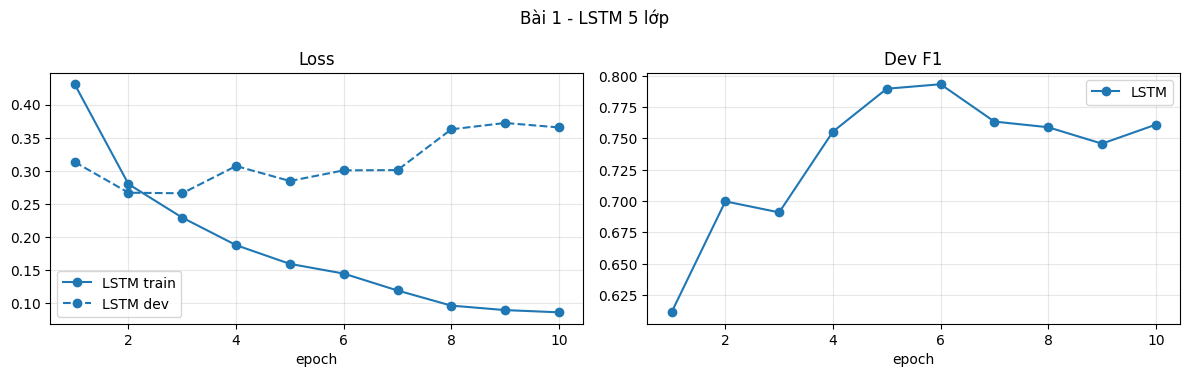

,Mô hình,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,LSTM 5 lớp,0.9018,0.7969,0.723,0.7459


,Lớp,Precision,Recall,F1,Số câu
0,negative,0.9100,0.9255,0.9177,1409
1,neutral,0.5682,0.2994,0.3922,167
2,positive,0.9125,0.9440,0.9280,1590


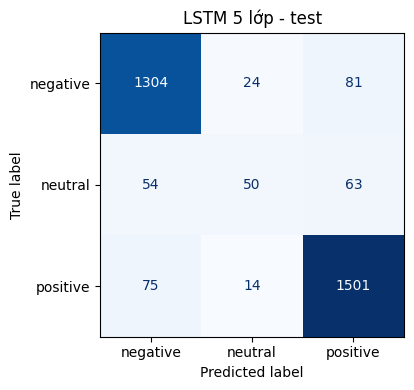

In [14]:
plot_history({"LSTM": lstm_hist}, "Bài 1 - LSTM 5 lớp")

# chấm test 1 lần với checkpoint đã chọn theo dev
lstm_gold, lstm_pred = predict_sentiment(lstm_model, cls_loader["test"])
lstm_test, lstm_test_cls = report_cls("LSTM 5 lớp", lstm_gold, lstm_pred)
display(pd.DataFrame([lstm_test]).round(4))
display(lstm_test_cls.round(4))
plot_cm(lstm_gold, lstm_pred, "LSTM 5 lớp - test")

In [15]:
# phân tích câu bị đoán sai trên dev
lstm_dev_gold, lstm_dev_pred = predict_sentiment(lstm_model, cls_loader["dev"])
show_wrong(lstm_dev_gold, lstm_dev_pred, cls_data["dev"].texts)

Số câu dev bị đoán sai: 116/1583


,Nhãn thật,Dự đoán,số câu
0,negative,neutral,12
1,negative,positive,29
2,neutral,negative,19
3,neutral,positive,24
4,positive,negative,25
5,positive,neutral,7


,Câu,Nhãn thật,Dự đoán
18,em không có bất cứ một lời phê bình nào .,neutral,negative
23,truyền đạt kiến thức .,neutral,positive
28,ôn tập kỹ trước khi thi hoặc trong lúc giảng dạy cập nhật đến những vấn đề có thể cho ra trong bài thi .,negative,positive
30,"thầy cho tự tìm hiểu , và tự tìm hiểu khác với hiểu được vấn đề .",neutral,positive
31,"cô dạy đều , bao giờ cũng đến sớm và đúng giờ .",positive,negative
51,cô rất nghiêm .,negative,positive


**Nhận xét Bài 1:**

- Mô hình có 3,138,007 tham số. Phần LSTM 5 lớp chiếm 2,676,736, đúng với số em tính tay. Embedding có 460,500 tham số (1535 từ x 300 chiều). Lớp Linear cuối chỉ có 771.
- Dev F1 tăng đều tới epoch 6 (0.7932) rồi giảm lại còn khoảng 0.76. Trong khi đó train loss vẫn giảm từ 0.43 xuống 0.086, còn dev loss thấp nhất ở epoch 3 (0.2659) rồi tăng lên khoảng 0.36. Như vậy từ khoảng epoch 6 trở đi mô hình bắt đầu overfit, nên chọn checkpoint theo dev là hợp lý.
- Trên test: accuracy 0.9018, precision 0.7969, recall 0.7230, macro-F1 0.7459. Mỗi epoch mất khoảng 6.1s trên T4.
- So với baseline TF-IDF (test macro-F1 0.6720), LSTM cao hơn khoảng 0.074. Accuracy 2 bên lại gần nhau (0.9018 so với 0.8917). Phần chênh chủ yếu nằm ở lớp neutral: F1 neutral tăng từ 0.1895 lên 0.3922. Vì vậy với dữ liệu lệch lớp như này thì phải nhìn macro-F1, nhìn accuracy sẽ không thấy được khác biệt.
- Lớp neutral vẫn là lớp yếu nhất. Recall chỉ 0.2994, tức 10 câu neutral thì mô hình bắt được khoảng 3 câu. Lý do là neutral chỉ chiếm 4% tập train (458/11426 câu). Hai lớp negative và positive đều có F1 trên 0.91.
- Phân tích câu đoán sai trên dev (116/1583 câu). Nhầm nhiều nhất là negative thành positive (29 câu) và positive thành negative (25 câu). Một vài câu em thấy đáng chú ý:
    - "em không có bất cứ một lời phê bình nào ." (neutral, đoán negative): câu có "không" và "phê bình" là những từ hay đi với câu chê, nhưng nghĩa cả câu là không có ý kiến gì. Mô hình chưa hiểu được phủ định của cả cụm.
    - "cô rất nghiêm ." (negative, đoán positive): "rất" thường đi với câu khen như "rất hay", "rất nhiệt tình", còn "nghiêm" thì khen hay chê đều được. Câu này người đọc cũng khó đoán.
    - "thầy cho tự tìm hiểu , và tự tìm hiểu khác với hiểu được vấn đề ." (neutral, đoán positive): ý chê nằm ẩn trong câu, không có từ chê rõ ràng nào.
    - "ôn tập kỹ trước khi thi hoặc ... cập nhật đến những vấn đề có thể cho ra trong bài thi ." (negative, đoán positive): đây là câu góp ý nhưng toàn từ nghe tích cực ("ôn tập kỹ", "cập nhật").
- Các câu sai chủ yếu là câu chê hoặc góp ý gián tiếp, hoặc câu có nhãn khá mơ hồ. Mô hình chỉ học từ từng chữ, chưa nắm được ý của cả câu.

## 4. Bài 2: GRU 5 lớp và so sánh với LSTM

In [16]:
set_seed(CFG["seed"])                 # khởi tạo lại seed, model và optimizer mới
gru_model = GRUSentiment(len(sent_vocab), **MODEL_KW)
print(f"Tổng tham số       : {count_params(gru_model):,}")
print(f"  GRU 5 lớp        : {count_params(gru_model.encoder.rnn):,} "
      f"(tính tay: {rnn_params_by_hand(3, CFG['emb_dim'], CFG['hidden'], CFG['layers']):,})")
gru_trainer = Trainer("gru_5layers", gru_model, cls_loss, dev_macro_f1)
gru_hist = gru_trainer.fit(cls_loader["train"], cls_loader["dev"])

Tổng tham số       : 2,468,823
  GRU 5 lớp        : 2,007,552 (tính tay: 2,007,552)
[gru_5layers] epoch  1 | train loss 0.3848 | dev loss 0.2798 | dev F1 0.6838 |   5.1s  <- tốt nhất
[gru_5layers] epoch  2 | train loss 0.2648 | dev loss 0.2864 | dev F1 0.7813 |   5.9s  <- tốt nhất
[gru_5layers] epoch  3 | train loss 0.2151 | dev loss 0.2844 | dev F1 0.7532 |   5.0s
[gru_5layers] epoch  4 | train loss 0.1852 | dev loss 0.2693 | dev F1 0.7635 |   5.9s
[gru_5layers] epoch  5 | train loss 0.1559 | dev loss 0.2892 | dev F1 0.7628 |   5.1s
[gru_5layers] epoch  6 | train loss 0.1305 | dev loss 0.3005 | dev F1 0.7701 |   5.4s
[gru_5layers] epoch  7 | train loss 0.1136 | dev loss 0.2889 | dev F1 0.7926 |   5.2s  <- tốt nhất
[gru_5layers] epoch  8 | train loss 0.0979 | dev loss 0.3527 | dev F1 0.7919 |   5.1s
[gru_5layers] epoch  9 | train loss 0.0939 | dev loss 0.3296 | dev F1 0.7800 |   5.7s
[gru_5layers] epoch 10 | train loss 0.0787 | dev loss 0.3717 | dev F1 0.7891 |   5.1s
Chọn epoch 7 (dev

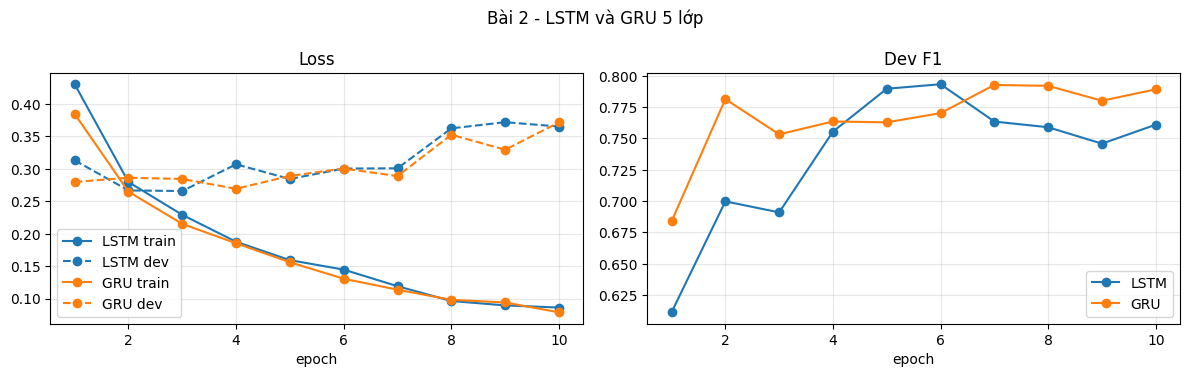

,Mô hình,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,GRU 5 lớp,0.9033,0.7926,0.7413,0.7596


,Lớp,Precision,Recall,F1,Số câu
0,negative,0.8909,0.9560,0.9223,1409
1,neutral,0.5463,0.3533,0.4291,167
2,positive,0.9405,0.9145,0.9273,1590


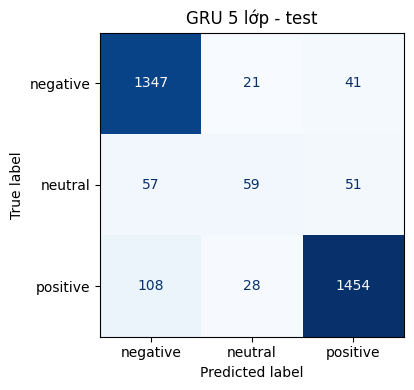

In [17]:
plot_history({"LSTM": lstm_hist, "GRU": gru_hist}, "Bài 2 - LSTM và GRU 5 lớp")

gru_gold, gru_pred = predict_sentiment(gru_model, cls_loader["test"])
gru_test, gru_test_cls = report_cls("GRU 5 lớp", gru_gold, gru_pred)
display(pd.DataFrame([gru_test]).round(4))
display(gru_test_cls.round(4))
plot_cm(gru_gold, gru_pred, "GRU 5 lớp - test")

In [18]:
gru_dev_gold, gru_dev_pred = predict_sentiment(gru_model, cls_loader["dev"])
show_wrong(gru_dev_gold, gru_dev_pred, cls_data["dev"].texts)

Số câu dev bị đoán sai: 124/1583


,Nhãn thật,Dự đoán,số câu
0,negative,neutral,15
1,negative,positive,18
2,neutral,negative,19
3,neutral,positive,20
4,positive,negative,37
5,positive,neutral,15


,Câu,Nhãn thật,Dự đoán
18,em không có bất cứ một lời phê bình nào .,neutral,negative
21,cách nói chuyện với sinh viên gây mất cảm tình của sinh viên đối với giảng viên .,negative,positive
30,"thầy cho tự tìm hiểu , và tự tìm hiểu khác với hiểu được vấn đề .",neutral,positive
51,cô rất nghiêm .,negative,positive
52,"đề cập về tính thực tế , liên quan của hệ thống kiến thức .",positive,neutral
72,thúc đẩy sinh viên tự học đạt điểm cao trong các kỳ thi .,positive,negative


In [19]:
# bảng so sánh 3 mô hình phân loại
rows = []
for name, test, trainer in [("TF-IDF + LogReg", tfidf_test, None),
                            ("LSTM 5 lớp", lstm_test, lstm_trainer),
                            ("GRU 5 lớp", gru_test, gru_trainer)]:
    rows.append({"Mô hình": name,
                 "Dev F1 tốt nhất": tfidf_dev_f1 if trainer is None else trainer.best_f1,
                 "Epoch tốt nhất": "-" if trainer is None else trainer.best_epoch,
                 "Test accuracy": test["Accuracy"], "Test F1 (macro)": test["F1 (macro)"],
                 "Tham số": "-" if trainer is None else f"{count_params(trainer.model):,}",
                 "Giây/epoch": f"{tfidf_seconds:.1f} (fit)" if trainer is None else round(trainer.sec_per_epoch, 1)})
compare_cls = pd.DataFrame(rows)
display(compare_cls.round(4))

f1_by_class = pd.DataFrame({"Lớp": LABELS, "TF-IDF": tfidf_test_cls["F1"],
                            "LSTM": lstm_test_cls["F1"], "GRU": gru_test_cls["F1"]})
display(f1_by_class.round(4))

,Mô hình,Dev F1 tốt nhất,Epoch tốt nhất,Test accuracy,Test F1 (macro),Tham số,Giây/epoch
0,TF-IDF + LogReg,0.7123,-,0.8917,0.6720,-,3.2 (fit)
1,LSTM 5 lớp,0.7932,6,0.9018,0.7459,"3,138,007",6.1
2,GRU 5 lớp,0.7926,7,0.9033,0.7596,"2,468,823",5.4


,Lớp,TF-IDF,LSTM,GRU
0,negative,0.9065,0.9177,0.9223
1,neutral,0.1895,0.3922,0.4291
2,positive,0.9200,0.9280,0.9273


**Nhận xét Bài 2:**

- GRU có 2,468,823 tham số. Phần GRU 5 lớp là 2,007,552, đúng bằng 3/4 phần LSTM vì GRU chỉ có 3 bộ trọng số thay vì 4. Tổng cộng GRU ít hơn LSTM 669,184 tham số.
- GRU cũng chạy nhanh hơn: 5.4s/epoch so với 6.1s/epoch của LSTM, nhanh hơn khoảng 11%.
- Trên dev, 2 mô hình gần như bằng nhau: GRU tốt nhất ở epoch 7 (0.7926), LSTM tốt nhất ở epoch 6 (0.7932). GRU học nhanh hơn ở đầu, mới epoch 2 đã đạt 0.7813.
- Trên test, GRU nhỉnh hơn một chút: macro-F1 0.7596 so với 0.7459, accuracy 0.9033 so với 0.9018. Phần hơn vẫn đến từ lớp neutral (F1 0.4291 so với 0.3922, recall 0.3533 so với 0.2994).
- Cả 2 đều overfit giống nhau. Tới epoch 10 thì train loss còn khoảng 0.08, còn dev loss tăng lên khoảng 0.37.
- Trên dev, GRU sai 124 câu, nhiều hơn LSTM (116 câu), chủ yếu do đoán positive thành negative (37 câu). Nhưng GRU lại đoán neutral tốt hơn, nên macro-F1 vẫn cao hơn. Có những câu cả 2 mô hình cùng sai, ví dụ "em không có bất cứ một lời phê bình nào ." và "cô rất nghiêm .". Đây là những câu khó thật, không phải lỗi riêng của một mô hình.
- Bảng tổng hợp cho thấy cả LSTM và GRU đều hơn baseline TF-IDF khoảng 0.07 đến 0.09 macro-F1.
- Theo em, với bài này GRU là lựa chọn hợp lý hơn: ít tham số, nhanh hơn mà kết quả không thua. Tuy nhiên chênh lệch trên test chỉ khoảng 0.014 và em mới chạy 1 seed, nên chưa thể kết luận GRU luôn tốt hơn LSTM.

## 5. Bài 3: Encoder 5 lớp BiLSTM cho NER (PhoNER_COVID19)

Mỗi token được gán 1 trong 21 nhãn BIO. Nhãn đệm là -100 và được loss bỏ qua. Điểm chính là entity F1 (micro, strict IOB2) bằng seqeval: 1 thực thể chỉ tính đúng khi đúng cả loại lẫn 2 biên.

In [20]:
TAGS = sorted({t for r in phoner["train"] for t in r["tags"]})
TAG2ID = {t: i for i, t in enumerate(TAGS)}
ID2TAG = dict(enumerate(TAGS))
assert len(TAGS) == 21 and all(t in TAG2ID for s in ["dev", "test"] for r in phoner[s] for t in r["tags"])

ner_vocab = Vocab.from_corpus(r["words"] for r in phoner["train"])
ner_data = {s: NerData(phoner[s], ner_vocab, TAG2ID) for s in SPLITS}
ner_loader = {s: make_loader(ner_data[s], shuffle=(s == "train")) for s in SPLITS}

entity_types = sorted({t[2:] for t in TAGS if t != "O"})
print("Số nhãn:", len(TAGS), "| loại thực thể:", entity_types)
print("Kích thước từ điển PhoNER:", len(ner_vocab))
x, lengths, y = next(iter(ner_loader["train"]))
print("1 batch:", tuple(x.shape), tuple(y.shape), "| số ô đệm -100:", (y == IGNORE).sum().item())

Số nhãn: 21 | loại thực thể: ['AGE', 'DATE', 'GENDER', 'JOB', 'LOCATION', 'NAME', 'ORGANIZATION', 'PATIENT_ID', 'SYMPTOM_AND_DISEASE', 'TRANSPORTATION']
Kích thước từ điển PhoNER: 2813
1 batch: (32, 62) (32, 62) | số ô đệm -100: 1012


In [21]:
ner_ce = nn.CrossEntropyLoss(ignore_index=IGNORE)

def ner_loss(logits, y):
    return ner_ce(logits.reshape(-1, logits.size(-1)), y.reshape(-1))

@torch.no_grad()
def predict_tags(model, loader):
    model.eval()
    gold, pred = [], []
    for ids, lengths, y in loader:
        out = model(ids.to(DEVICE), lengths).argmax(-1).cpu()
        for g, p, n in zip(y, out, lengths.tolist()):
            # cắt theo độ dài thật trước khi đổi id sang nhãn, bỏ phần đệm
            gold.append([ID2TAG[i] for i in g[:n].tolist()])
            pred.append([ID2TAG[i] for i in p[:n].tolist()])
    return gold, pred

def dev_entity_f1(model, loader):
    gold, pred = predict_tags(model, loader)
    return seq_f1(gold, pred, mode="strict", scheme=IOB2, zero_division=0)

set_seed(CFG["seed"])
ner_model = BiLSTMTagger(len(ner_vocab), len(TAGS), **MODEL_KW)
print(f"Tổng tham số          : {count_params(ner_model):,}")
print(f"  embedding           : {ner_model.encoder.embedding.weight.numel():,}")
print(f"  BiLSTM 5 lớp        : {count_params(ner_model.encoder.rnn):,} "
      f"(tính tay: {rnn_params_by_hand(4, CFG['emb_dim'], CFG['hidden'], CFG['layers'], True):,})")
print(f"  Linear 512 -> 21    : {count_params(ner_model.head):,}")

Tổng tham số          : 8,305,297
  embedding           : 843,900
  BiLSTM 5 lớp        : 7,450,624 (tính tay: 7,450,624)
  Linear 512 -> 21    : 10,773


In [22]:
ner_trainer = Trainer("bilstm_ner_5layers", ner_model, ner_loss, dev_entity_f1)
ner_hist = ner_trainer.fit(ner_loader["train"], ner_loader["dev"])

[bilstm_ner_5layers] epoch  1 | train loss 0.7545 | dev loss 0.4015 | dev F1 0.5534 |   6.8s  <- tốt nhất
[bilstm_ner_5layers] epoch  2 | train loss 0.1889 | dev loss 0.1928 | dev F1 0.8255 |   7.3s  <- tốt nhất
[bilstm_ner_5layers] epoch  3 | train loss 0.0969 | dev loss 0.1702 | dev F1 0.8526 |   6.8s  <- tốt nhất
[bilstm_ner_5layers] epoch  4 | train loss 0.0661 | dev loss 0.1453 | dev F1 0.8832 |   6.4s  <- tốt nhất
[bilstm_ner_5layers] epoch  5 | train loss 0.0482 | dev loss 0.1554 | dev F1 0.8836 |  14.6s  <- tốt nhất
[bilstm_ner_5layers] epoch  6 | train loss 0.0373 | dev loss 0.1552 | dev F1 0.8881 |   6.5s  <- tốt nhất
[bilstm_ner_5layers] epoch  7 | train loss 0.0324 | dev loss 0.1795 | dev F1 0.8866 |   7.4s
[bilstm_ner_5layers] epoch  8 | train loss 0.0277 | dev loss 0.1795 | dev F1 0.8903 |   7.3s  <- tốt nhất
[bilstm_ner_5layers] epoch  9 | train loss 0.0222 | dev loss 0.1690 | dev F1 0.8994 |   6.6s  <- tốt nhất
[bilstm_ner_5layers] epoch 10 | train loss 0.0172 | dev los

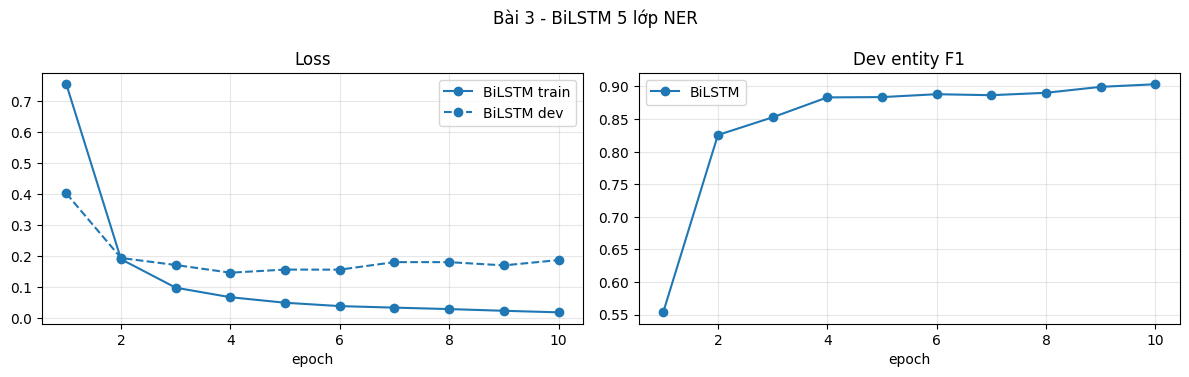

,Precision,Recall,F1 (micro)
0,0.9011,0.8851,0.893


                     precision    recall  f1-score   support

                AGE     0.9456    0.9261    0.9358       582
               DATE     0.9628    0.9547    0.9587      1654
             GENDER     0.9483    0.9134    0.9305       462
                JOB     0.6167    0.4277    0.5051       173
           LOCATION     0.9053    0.9020    0.9037      4441
               NAME     0.6901    0.6164    0.6512       318
       ORGANIZATION     0.8083    0.7821    0.7950       771
         PATIENT_ID     0.9310    0.9626    0.9465      2005
SYMPTOM_AND_DISEASE     0.8377    0.7676    0.8011      1136
     TRANSPORTATION     0.9071    0.8601    0.8830       193

          micro avg     0.9011    0.8851    0.8930     11735
          macro avg     0.8553    0.8113    0.8311     11735
       weighted avg     0.8985    0.8851    0.8913     11735



In [23]:
plot_history({"BiLSTM": ner_hist}, "Bài 3 - BiLSTM 5 lớp NER", metric="entity F1")

ner_gold, ner_pred = predict_tags(ner_model, ner_loader["test"])
ner_test = {"Precision": seq_precision(ner_gold, ner_pred, mode="strict", scheme=IOB2, zero_division=0),
            "Recall": seq_recall(ner_gold, ner_pred, mode="strict", scheme=IOB2, zero_division=0),
            "F1 (micro)": seq_f1(ner_gold, ner_pred, mode="strict", scheme=IOB2, zero_division=0)}
display(pd.DataFrame([ner_test]).round(4))
print(seq_report(ner_gold, ner_pred, mode="strict", scheme=IOB2, digits=4, zero_division=0))

In [24]:
# đếm các kiểu lỗi trên dev, chỉ in số lượng (không in câu của PhoNER)
def get_spans(tags):
    spans, start, typ = [], None, None
    for i, t in enumerate(tags + ["O"]):
        if start is not None and t != "I-" + typ:
            spans.append((typ, start, i))
            start = None
        if t.startswith("B-"):
            start, typ = i, t[2:]
    return spans

def error_types(gold_seqs, pred_seqs):
    counts = Counter()
    by_type = Counter()
    for g_tags, p_tags in zip(gold_seqs, pred_seqs):
        g_spans, p_spans = get_spans(g_tags), get_spans(p_tags)
        p_set = set(p_spans)
        for typ, s, e in g_spans:
            if (typ, s, e) in p_set:
                counts["đúng"] += 1
                continue
            overlap = [p for p in p_spans if p[1] < e and s < p[2]]
            if any(p[1:] == (s, e) for p in overlap):
                kind = "sai loại (đúng biên)"
            elif any(p[0] == typ for p in overlap):
                kind = "sai biên (đúng loại)"
            elif overlap:
                kind = "sai cả biên và loại"
            else:
                kind = "bỏ sót"
            counts[kind] += 1
            by_type[(typ, kind)] += 1
        for typ, s, e in p_spans:
            if not any(g[1] < e and s < g[2] for g in g_spans):
                counts["đoán thừa"] += 1
                by_type[(typ, "đoán thừa")] += 1
    return counts, by_type

dev_gold_tags, dev_pred_tags = predict_tags(ner_model, ner_loader["dev"])
err_counts, err_by_type = error_types(dev_gold_tags, dev_pred_tags)
display(pd.DataFrame(err_counts.most_common(), columns=["Kết quả trên dev", "Số thực thể"]))
err_table = (pd.Series(err_by_type, dtype=int).rename("số lỗi").reset_index()
             .rename(columns={"level_0": "Loại thực thể", "level_1": "Kiểu lỗi"})
             .pivot(index="Loại thực thể", columns="Kiểu lỗi", values="số lỗi").fillna(0).astype(int))
display(err_table)

,Kết quả trên dev,Số thực thể
0,đúng,6709
1,bỏ sót,350
2,sai biên (đúng loại),241
3,đoán thừa,220
4,sai loại (đúng biên),139
5,sai cả biên và loại,39


Kiểu lỗi,bỏ sót,sai biên (đúng loại),sai cả biên và loại,sai loại (đúng biên),đoán thừa
Loại thực thể,,,,,
AGE,16,0,0,8,11
DATE,12,8,2,21,14
GENDER,22,1,0,2,8
JOB,51,14,1,0,14
LOCATION,75,115,8,21,32
NAME,32,6,2,39,21
ORGANIZATION,18,31,14,39,31
PATIENT_ID,43,5,1,4,25
SYMPTOM_AND_DISEASE,77,61,8,3,62


**Nhận xét Bài 3:**

- Mô hình có 8,305,297 tham số, nhiều gấp khoảng 2.6 lần LSTM ở Bài 1:
    - BiLSTM 5 lớp: 7,450,624, đúng với tính tay. Mỗi lớp có 2 chiều, và từ lớp 2 trở đi đầu vào là 512 chiều.
    - Embedding: 843,900 (2813 từ x 300).
    - Linear 512 -> 21: 10,773.
- Mỗi epoch mất khoảng 7.7s.
- Mô hình học rất nhanh. Entity F1 trên dev là 0.5534 ở epoch 1, 0.8255 ở epoch 2, rồi tăng chậm dần tới 0.9034 ở epoch 10 (epoch tốt nhất). Dev loss thấp nhất ở epoch 4 (0.1453) rồi dao động quanh 0.15 đến 0.19. Như vậy có overfit nhẹ, nhưng F1 vẫn còn tăng, có thể train thêm vài epoch nữa thì F1 còn lên chút.
- Trên test: precision 0.9011, recall 0.8851, entity micro-F1 0.8930.
- Các loại thực thể có mẫu rõ ràng thì làm rất tốt:
    - DATE 0.9587, PATIENT_ID 0.9465, AGE 0.9358, GENDER 0.9305
    - Các loại này thường có số, có chữ "tuổi", "nam", "nữ", "BN" đi kèm nên dễ nhận ra.
- Các loại yếu hơn:
    - JOB 0.5051: ít mẫu (173 trên test), cách viết nghề nghiệp lại rất đa dạng.
    - NAME 0.6512: tên người hiếm khi lặp lại, nhiều tên bị biến thành UNK vì từ điển chỉ giữ từ xuất hiện từ 2 lần.
    - ORGANIZATION 0.7950, SYMPTOM_AND_DISEASE 0.8011.
- Phân tích lỗi trên dev, tổng 7478 thực thể:
    - Đúng: 6709
    - Bỏ sót: 350
    - Sai biên nhưng đúng loại: 241
    - Đoán thừa: 220
    - Đúng biên nhưng sai loại: 139
    - Sai cả biên lẫn loại: 39
- Em minh họa 3 kiểu lỗi chính bằng ví dụ tự tạo, không lấy câu trong PhoNER:
    - **Sai biên** (nhiều nhất ở LOCATION 115 lỗi, SYMPTOM_AND_DISEASE 61 lỗi). Ví dụ câu "Bệnh nhân sống ở phường Linh Trung , thành phố Thủ Đức". Nhãn đúng là cả cụm "phường Linh Trung" là LOCATION. Lỗi sai biên là khi mô hình chỉ gán được "Linh Trung", thiếu chữ "phường" ở đầu. Theo chuẩn strict thì thực thể đó tính là sai hoàn toàn. Thực thể càng dài (địa chỉ, tên bệnh nhiều chữ) thì càng dễ sai biên.
    - **Bỏ sót** (nhiều nhất ở SYMPTOM_AND_DISEASE 77, LOCATION 75, JOB 51). Ví dụ "Bệnh nhân làm nhân viên giao hàng": "nhân viên giao hàng" là JOB. Bỏ sót là khi mô hình gán O cho cả cụm. Với JOB, số lỗi bỏ sót trên dev (51) chiếm gần 40% số thực thể JOB, nên đây là điểm yếu lớn nhất của mô hình.
    - **Sai loại** (nhiều nhất ở NAME 39, ORGANIZATION 39). Ví dụ "Bệnh nhân được điều trị tại Bệnh viện Chợ Rẫy". "Bệnh viện Chợ Rẫy" là ORGANIZATION. Sai loại là khi mô hình đoán đúng cả cụm nhưng gán thành LOCATION, vì cụm này đứng sau "tại", giống cách viết địa điểm. Theo em, tên người hay bị nhầm loại vì nhiều tên người trùng với tên đường hoặc địa danh.
- Ngoài ra còn 220 lỗi đoán thừa, nhiều nhất ở SYMPTOM_AND_DISEASE (62). Tức là mô hình gắn nhãn bệnh cho cả những cụm mà dữ liệu không đánh dấu là thực thể.
- So với notebook thực hành (BiLSTM 1 lớp, hidden 64, 3 epoch, dev F1 0.7233), bản 5 lớp hidden 256 cao hơn khoảng 0.18. Phần cải thiện lớn nhất là JOB và NAME: ở bản nhỏ 2 loại này có F1 bằng 0.

## 6. Bài 4 (tùy chọn): ảnh hưởng của số lớp

Hướng (a) của đề: GRU với num_layers = 1, 2, 5, giữ hidden 256 và mọi cấu hình khác như Bài 2. Kết quả 5 lớp lấy lại từ Bài 2.

In [25]:
depth_rows = []
for n_layers in [1, 2, 5]:
    if n_layers == 5:
        trainer = gru_trainer
    else:
        set_seed(CFG["seed"])
        model = GRUSentiment(len(sent_vocab), **{**MODEL_KW, "layers": n_layers})
        trainer = Trainer(f"gru_{n_layers}layers", model, cls_loss, dev_macro_f1)
        trainer.fit(cls_loader["train"], cls_loader["dev"])
    gold, pred = predict_sentiment(trainer.model, cls_loader["test"])
    test, test_cls = report_cls(f"GRU {n_layers} lớp", gold, pred)
    depth_rows.append({"Số lớp": n_layers, "Tham số": f"{count_params(trainer.model):,}",
                       "Dev F1 tốt nhất": trainer.best_f1, "Epoch tốt nhất": trainer.best_epoch,
                       "Test F1 (macro)": test["F1 (macro)"],
                       "F1 neutral": test_cls.loc[1, "F1"],
                       "Giây/epoch": round(trainer.sec_per_epoch, 1)})
depth_table = pd.DataFrame(depth_rows)
display(depth_table.round(4))

[gru_1layers] epoch  1 | train loss 0.3769 | dev loss 0.2833 | dev F1 0.7250 |   2.1s  <- tốt nhất
[gru_1layers] epoch  2 | train loss 0.2291 | dev loss 0.2473 | dev F1 0.7983 |   2.1s  <- tốt nhất
[gru_1layers] epoch  3 | train loss 0.1635 | dev loss 0.2599 | dev F1 0.7775 |   2.1s
[gru_1layers] epoch  4 | train loss 0.1134 | dev loss 0.2839 | dev F1 0.7889 |   2.2s
[gru_1layers] epoch  5 | train loss 0.0734 | dev loss 0.3235 | dev F1 0.7956 |   2.6s
[gru_1layers] epoch  6 | train loss 0.0487 | dev loss 0.3678 | dev F1 0.7829 |   2.0s
[gru_1layers] epoch  7 | train loss 0.0293 | dev loss 0.3977 | dev F1 0.7912 |   2.1s
[gru_1layers] epoch  8 | train loss 0.0185 | dev loss 0.4371 | dev F1 0.7817 |   2.2s
[gru_1layers] epoch  9 | train loss 0.0138 | dev loss 0.5094 | dev F1 0.7946 |   2.1s
[gru_1layers] epoch 10 | train loss 0.0132 | dev loss 0.4603 | dev F1 0.7771 |   2.8s
Chọn epoch 2 (dev F1 = 0.7983), trung bình 2.2 s/epoch
[gru_2layers] epoch  1 | train loss 0.3629 | dev loss 0.259

,Số lớp,Tham số,Dev F1 tốt nhất,Epoch tốt nhất,Test F1 (macro),F1 neutral,Giây/epoch
0,1,"889,815",0.7983,2,0.7386,0.3710,2.2
1,2,"1,284,567",0.7958,9,0.7537,0.4145,3.0
2,5,"2,468,823",0.7926,7,0.7596,0.4291,5.4


**Nhận xét Bài 4:**

| Số lớp | Tham số | Dev F1 | Test F1 | F1 neutral | Giây/epoch |
|---|---|---|---|---|---|
| 1 | 889,815 | 0.7983 | 0.7386 | 0.3710 | 2.2 |
| 2 | 1,284,567 | 0.7958 | 0.7537 | 0.4145 | 3.0 |
| 5 | 2,468,823 | 0.7926 | 0.7596 | 0.4291 | 5.4 |

- Trên dev, 3 mức độ sâu gần như bằng nhau (0.79 đến 0.80), thậm chí 1 lớp còn cao nhất. Trên test thì ngược lại: càng nhiều lớp càng tốt hơn một chút, từ 0.7386 lên 0.7596, và F1 neutral cũng tăng theo. Chênh lệch đều nhỏ (khoảng 0.02), dev và test lại xếp hạng khác nhau. Vì vậy em không kết luận được là sâu hơn chắc chắn tốt hơn.
- Điểm khác rõ nhất là tốc độ overfit:
    - 1 lớp tốt nhất ngay epoch 2. Sau đó train loss xuống còn 0.013, còn dev loss tăng từ 0.2473 lên khoảng 0.46.
    - Mạng 5 lớp overfit chậm hơn: train loss ở epoch 10 vẫn còn 0.0787.
    - Một lý do là dropout 0.3 của nn.GRU chỉ áp dụng giữa các lớp, nên mạng 1 lớp gần như không có dropout bên trong.
- Chi phí tăng khá nhanh. Từ 1 lên 5 lớp, số tham số tăng gần 2.8 lần và thời gian mỗi epoch tăng khoảng 2.5 lần.
- Khi thêm lớp thì số tham số cũng tăng theo, nên em chưa tách được kết quả thay đổi là do độ sâu hay do số tham số. Muốn tách ra thì cần so thêm mạng 1 lớp có hidden lớn hơn để số tham số bằng nhau. Ngoài ra cần chạy thêm vài seed mới kết luận chắc được.

## 7. Tổng hợp kết quả

In [26]:
summary = pd.DataFrame([
    {"Mô hình": "TF-IDF + Logistic Regression", "Dev F1 tốt nhất": tfidf_dev_f1,
     "Test F1": tfidf_test["F1 (macro)"], "Độ đo": "macro-F1",
     "Tham số": "ngram (1, 2), min_df 2", "Giây/epoch": f"{tfidf_seconds:.1f} (fit)"},
    {"Mô hình": "LSTM 5 lớp", "Dev F1 tốt nhất": lstm_trainer.best_f1,
     "Test F1": lstm_test["F1 (macro)"], "Độ đo": "macro-F1",
     "Tham số": f"{count_params(lstm_model):,}", "Giây/epoch": round(lstm_trainer.sec_per_epoch, 1)},
    {"Mô hình": "GRU 5 lớp", "Dev F1 tốt nhất": gru_trainer.best_f1,
     "Test F1": gru_test["F1 (macro)"], "Độ đo": "macro-F1",
     "Tham số": f"{count_params(gru_model):,}", "Giây/epoch": round(gru_trainer.sec_per_epoch, 1)},
    {"Mô hình": "BiLSTM NER 5 lớp", "Dev F1 tốt nhất": ner_trainer.best_f1,
     "Test F1": ner_test["F1 (micro)"], "Độ đo": "entity micro-F1",
     "Tham số": f"{count_params(ner_model):,}", "Giây/epoch": round(ner_trainer.sec_per_epoch, 1)},
])
display(summary.round(4))

,Mô hình,Dev F1 tốt nhất,Test F1,Độ đo,Tham số,Giây/epoch
0,TF-IDF + Logistic Regression,0.7123,0.6720,macro-F1,"ngram (1, 2), min_df 2",3.2 (fit)
1,LSTM 5 lớp,0.7932,0.7459,macro-F1,"3,138,007",6.1
2,GRU 5 lớp,0.7926,0.7596,macro-F1,"2,468,823",5.4
3,BiLSTM NER 5 lớp,0.9034,0.8930,entity micro-F1,"8,305,297",7.7


## Kết luận

- Với bài phân loại cảm xúc, cả LSTM và GRU 5 lớp đều tốt hơn baseline TF-IDF:
    - Test macro-F1: 0.7459 (LSTM) và 0.7596 (GRU), so với 0.6720 (TF-IDF).
    - Phần hơn chủ yếu đến từ lớp neutral, còn accuracy của 3 mô hình đều quanh 0.89 đến 0.90.
- GRU và LSTM cho kết quả gần như nhau. GRU ít hơn khoảng 670 nghìn tham số và chạy nhanh hơn khoảng 11%, nên ở bài này em sẽ chọn GRU.
- Lớp neutral là khó nhất. Lớp này chỉ chiếm 4% dữ liệu và F1 của mọi mô hình đều dưới 0.43. Nếu làm tiếp, em nghĩ nên thử thêm trọng số lớp cho loss hoặc oversampling lớp neutral.
- Với NER, encoder BiLSTM 5 lớp đạt entity F1 0.8930 trên test. Các loại có mẫu rõ (ngày, mã bệnh nhân, tuổi, giới tính) đạt trên 0.93. JOB và NAME còn yếu do ít dữ liệu và nhiều từ lạ.
- Mạng 5 lớp với dữ liệu khoảng 11 nghìn câu overfit khá sớm (sau khoảng epoch 6). Vì vậy việc chọn checkpoint theo dev rồi mới chấm test 1 lần là rất cần thiết.